# TREASURE: balance, deficit and reuse

you need`../Dataset/Q_tot.xlsx`, `../Dataset/Idro_Dataset.xlsx` and the file `../Results_Forecasting/Predictions_by_seed.csv` 

## 1. Data, balance and input table

In [9]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from sklearn.metrics import mean_absolute_error, mean_squared_error
from IPython.display import display
from sklearn.metrics import roc_auc_score

warnings.filterwarnings('ignore', category=UserWarning)

DATA_DIR = Path("..") / "Dataset" 
FORECASTS = Path("..") / 'Results_Forecasting'         
OUT = Path("..") / 'Results_Balance'
OUT.mkdir(parents=True, exist_ok=True)
REPORT_SEEDS = [42, 123, 2026]
TRAIN_RATIO, VAL_RATIO = 0.70, 0.15
LAST_MODEL_MONTH = '2022-12-01'                 

raw = pd.read_excel(DATA_DIR / 'Q_tot.xlsx', sheet_name=0, skiprows=[1])
balance = pd.DataFrame({
    'ds': pd.to_datetime(raw['Date']).dt.to_period('M').dt.to_timestamp(),
    'Q_tronto': raw['Q_tronto'], 'Q_aquifer': raw['Aquifer discharge'], 'Q_local': raw['Q_Inf+RO+Uro_S (m3/s)'],
    'MEF': raw['MEF'], 'Abstractions': raw['Authorized withdrawalsi (agr+ind+other)'],
    'Civil': raw['Civil water withdrawal'],
    'Lakes': raw['Lake water demand'], 'Agriculture': raw['Agricultural water demand'], 'WW': raw['WWTP']})
lakes_missing = balance.Lakes.isna()
balance['Lakes'] = balance.Lakes.fillna(0)
balance['Q_tot'] = balance.Q_tronto + balance.Q_aquifer + balance.Q_local
balance['Available'] = balance.Q_tot - balance.MEF
balance['Demand'] = balance.Abstractions + balance.Civil + balance.Lakes + balance.Agriculture
balance['Balance_no_reuse'] = balance.Available - balance.Demand
balance['Balance_reuse'] = balance.Balance_no_reuse + balance.WW
assert np.allclose(balance.Available, pd.to_numeric(raw['Net available discharge (-MEF)'])), 'Q disponibile diverso da Q_tot.xlsx'
assert np.allclose(balance.Balance_reuse, pd.to_numeric(raw['Q_available-Q_demand +wwtp'])), 'Bilancio diverso da Q_tot.xlsx'

seconds = balance.ds.dt.days_in_month * 86400
balance['Deficit_no_reuse'] = (-balance.Balance_no_reuse).clip(lower=0)
balance['Deficit_reuse'] = (-balance.Balance_reuse).clip(lower=0)
balance['Volume_no_reuse_Mm3'] = balance.Deficit_no_reuse * seconds / 1e6
balance['Volume_reuse_Mm3'] = balance.Deficit_reuse * seconds / 1e6
model_period = balance[balance.ds <= LAST_MODEL_MONTH].copy()


hydro = pd.read_excel(DATA_DIR / 'Idro_Dataset.xlsx', sheet_name=0)
hydro['ds'] = pd.to_datetime(hydro['Date']).dt.to_period('M').dt.to_timestamp()
check = model_period.merge(hydro[['ds', 'Q_Disp']], on='ds')

month = model_period.ds.dt.month
inputs_by_month = (model_period.groupby(month)
                   .agg(MEF=('MEF', 'mean'), Abstractions=('Abstractions', 'mean'), Lakes_mean=('Lakes', 'mean'),
                        Agriculture=('Agriculture', 'mean'), Demand_mean=('Demand', 'mean'), Demand_min=('Demand', 'min'),
                        Demand_max=('Demand', 'max'), WW_mean=('WW', 'mean'), WW_min=('WW', 'min'), WW_max=('WW', 'max'))
                   .rename_axis('Month').reset_index())
inputs_by_month.to_csv(OUT / 'Table_balance_inputs_by_month.csv', index=False)
inputs_by_year = model_period.groupby(model_period.ds.dt.year).agg(
    Available_mean=('Available', 'mean'), Demand_mean=('Demand', 'mean'), WW_mean=('WW', 'mean'),
    WW_min=('WW', 'min'), WW_max=('WW', 'max')).rename_axis('Year').reset_index()
inputs_by_year.to_csv(OUT / 'Table_balance_inputs_by_year.csv', index=False)

ww_profile = model_period.pivot_table(index=month, columns=model_period.ds.dt.year, values='WW')
identical_ww_years = [y for y in ww_profile.columns if np.allclose(ww_profile[y], ww_profile[ww_profile.columns[0]])]
agr_profile = model_period.pivot_table(index=month, columns=model_period.ds.dt.year, values='Agriculture')
data_checks = pd.DataFrame([
    dict(Check='WW: years with the same monthly profile as 2013', Result=', '.join(map(str, identical_ww_years))),
    dict(Check='Agriculture: same monthly profile in every year', Result=str(bool(np.allclose(agr_profile.sub(agr_profile.iloc[:, 0], axis=0), 0)))),
    dict(Check='Abstractions: constant value', Result=str(model_period.Abstractions.round(6).nunique() == 1)),
    dict(Check='Civil abstractions: all zero', Result=str(bool((balance.Civil == 0).all()))),
    dict(Check='Lakes: missing months', Result=f"{lakes_missing.sum()} months in {sorted(balance.ds[lakes_missing].dt.year.unique().tolist())}"),
    dict(Check='Mean demand / mean Q_tot', Result=f'{model_period.Demand.mean() / model_period.Q_tot.mean():.2%}'),
])
data_checks.to_csv(OUT / 'Input_data_checks.csv', index=False)
print('Controlli sugli input'); display(data_checks)
print('Input per anno'); display(inputs_by_year.round(3))
print('Input per mese di calendario'); display(inputs_by_month.round(3))


Controlli sugli input


,Check,Result
0,WW: years with the same monthly profile as 2013,"2013, 2014, 2015, 2016, 2017, 2018"
1,Agriculture: same monthly profile in every year,True
2,Abstractions: constant value,True
3,Civil abstractions: all zero,True
4,Lakes: missing months,12 months in [2023]
5,Mean demand / mean Q_tot,0.71%


Input per anno


,Year,Available_mean,Demand_mean,WW_mean,WW_min,WW_max
0,2013,11.083,0.103,0.311,0.270,0.379
1,2014,6.493,0.103,0.311,0.270,0.379
2,2015,7.738,0.103,0.311,0.270,0.379
3,2016,8.368,0.103,0.311,0.270,0.379
4,2017,13.505,0.103,0.311,0.270,0.379
5,2018,18.017,0.103,0.311,0.270,0.379
6,2019,9.770,0.103,0.292,0.263,0.341
7,2020,3.469,0.103,0.264,0.217,0.332
8,2021,11.602,0.103,0.230,0.175,0.303
9,2022,8.382,0.103,0.192,0.134,0.270


Input per mese di calendario


,Month,MEF,Abstractions,Lakes_mean,Agriculture,Demand_mean,Demand_min,Demand_max,WW_mean,WW_min,WW_max
0,1,5.04,0.046,0.025,0.000,0.071,0.046,0.086,0.258,0.200,0.272
1,2,5.81,0.046,0.025,0.000,0.071,0.046,0.086,0.285,0.187,0.320
2,3,5.81,0.046,0.018,0.000,0.064,0.046,0.082,0.345,0.269,0.379
3,4,5.04,0.046,0.029,0.059,0.134,0.119,0.150,0.312,0.231,0.336
4,5,5.04,0.046,0.025,0.057,0.128,0.103,0.146,0.329,0.270,0.341
5,6,5.04,0.046,0.038,0.059,0.144,0.135,0.155,0.277,0.145,0.321
6,7,3.87,0.046,0.036,0.057,0.139,0.126,0.153,0.274,0.158,0.308
7,8,3.87,0.046,0.043,0.057,0.146,0.137,0.157,0.271,0.161,0.310
8,9,3.87,0.046,0.030,0.059,0.136,0.125,0.153,0.275,0.174,0.301
9,10,3.87,0.046,0.022,0.000,0.068,0.046,0.091,0.270,0.192,0.295


## 2. Observed deficit with and without reuse

In [10]:

def summarize_deficits(frame, label):
    return dict(Period=label, Months=len(frame),
                Deficit_months_no_reuse=int((frame.Deficit_no_reuse > 0).sum()),
                Deficit_months_reuse=int((frame.Deficit_reuse > 0).sum()),
                Months_eliminated=int(((frame.Deficit_no_reuse > 0) & (frame.Deficit_reuse == 0)).sum()),
                Volume_no_reuse_Mm3=frame.Volume_no_reuse_Mm3.sum(), Volume_reuse_Mm3=frame.Volume_reuse_Mm3.sum(),
                Volume_reduction_pct=100 * (1 - frame.Volume_reuse_Mm3.sum() / frame.Volume_no_reuse_Mm3.sum()) if frame.Volume_no_reuse_Mm3.sum() > 0 else np.nan,
                Max_deficit_no_reuse=frame.Deficit_no_reuse.max(), Max_deficit_reuse=frame.Deficit_reuse.max())


deficit_summary = pd.DataFrame([summarize_deficits(model_period, '2013-2022'), summarize_deficits(balance, '2013-2023')])
deficit_months = balance[balance.Deficit_no_reuse > 0][['ds', 'Q_tronto', 'MEF', 'Available', 'Demand', 'WW', 'Balance_no_reuse', 'Balance_reuse',
                                                        'Deficit_no_reuse', 'Deficit_reuse', 'Volume_no_reuse_Mm3', 'Volume_reuse_Mm3']].copy()
deficit_months['Deficit_without_demand'] = deficit_months.Available < 0
deficit_summary.to_csv(OUT / 'Deficit_summary.csv', index=False)
deficit_months.to_csv(OUT / 'Deficit_months.csv', index=False)
deficit_by_year = model_period.groupby(model_period.ds.dt.year).agg(
    Months_no_reuse=('Deficit_no_reuse', lambda s: int((s > 0).sum())), Months_reuse=('Deficit_reuse', lambda s: int((s > 0).sum())),
    Volume_no_reuse_Mm3=('Volume_no_reuse_Mm3', 'sum'), Volume_reuse_Mm3=('Volume_reuse_Mm3', 'sum')).rename_axis('Year').reset_index()
deficit_by_year.to_csv(OUT / 'Deficit_by_year.csv', index=False)
print('Sintesi dei deficit'); display(deficit_summary.round(3))
print('Mesi in deficit'); display(deficit_months.round(3))
print('Deficit per anno'); display(deficit_by_year.round(3))
index_check = balance[['ds', 'Available', 'Demand', 'WW']].copy()
index_check['DI_without'] = (balance.Available - balance.Demand) / balance.Available.abs()
index_check['DI_with'] = (balance.Available + balance.WW - balance.Demand) / balance.Available.abs()
index_check['Delta_figure'] = index_check.DI_with - index_check.DI_without.abs()
index_check['Delta_sheet'] = (index_check.DI_with - index_check.DI_without) / index_check.DI_without.abs()
assert np.allclose(index_check.DI_without, pd.to_numeric(raw['INDICE PRE'])) and np.allclose(index_check.DI_with, pd.to_numeric(raw['INDICE POST']))
index_extremes = index_check.loc[(index_check.DI_with.abs() > 2) | (index_check.DI_without.abs() > 2) | (index_check.Available.abs() < 0.1)].round(3)
index_extremes.to_csv(OUT / 'Demand_index_extreme_months.csv', index=False)
print('Valori estremi del vecchio indice'); display(index_extremes)


Sintesi dei deficit


,Period,Months,Deficit_months_no_reuse,Deficit_months_reuse,Months_eliminated,Volume_no_reuse_Mm3,Volume_reuse_Mm3,Volume_reduction_pct,Max_deficit_no_reuse,Max_deficit_reuse
0,2013-2022,120,8,7,1,18.032,13.792,23.514,1.488,1.241
1,2013-2023,132,8,7,1,18.032,13.792,23.514,1.488,1.241


Mesi in deficit


,ds,Q_tronto,MEF,Available,Demand,WW,Balance_no_reuse,Balance_reuse,Deficit_no_reuse,Deficit_reuse,Volume_no_reuse_Mm3,Volume_reuse_Mm3,Deficit_without_demand
22,2014-11-01,4.933,5.04,0.005,0.086,0.278,-0.082,0.196,0.082,0.000,0.211,0.000,False
23,2014-12-01,4.436,5.04,-0.492,0.074,0.270,-0.567,-0.297,0.567,0.297,1.517,0.795,True
89,2020-06-01,4.408,5.04,-0.520,0.141,0.238,-0.661,-0.422,0.661,0.422,1.712,1.095,True
90,2020-07-01,2.659,3.87,-1.099,0.140,0.217,-1.240,-1.023,1.240,1.023,3.320,2.739,True
91,2020-08-01,2.410,3.87,-1.348,0.140,0.247,-1.488,-1.241,1.488,1.241,3.985,3.323,True
92,2020-09-01,2.938,3.87,-0.820,0.143,0.240,-0.963,-0.722,0.963,0.722,2.496,1.872,True
118,2022-11-01,4.537,5.04,-0.391,0.049,0.134,-0.440,-0.306,0.440,0.306,1.141,0.794,True
119,2022-12-01,3.628,5.04,-1.300,0.062,0.177,-1.362,-1.185,1.362,1.185,3.649,3.174,True


Deficit per anno


,Year,Months_no_reuse,Months_reuse,Volume_no_reuse_Mm3,Volume_reuse_Mm3
0,2013,0,0,0.000,0.000
1,2014,2,1,1.729,0.795
2,2015,0,0,0.000,0.000
3,2016,0,0,0.000,0.000
4,2017,0,0,0.000,0.000
5,2018,0,0,0.000,0.000
6,2019,0,0,0.000,0.000
7,2020,4,4,11.513,9.029
8,2021,0,0,0.000,0.000
9,2022,2,2,4.790,3.967


Valori estremi del vecchio indice


,ds,Available,Demand,WW,DI_without,DI_with,Delta_figure,Delta_sheet
22,2014-11-01,0.005,0.086,0.278,-17.335,41.652,24.317,3.403
35,2015-12-01,0.087,0.087,0.270,0.004,3.095,3.091,777.470


## 3. Deficit forecasting with and without reuse

In [11]:

hydro_series = hydro[['ds', 'Q_Disp']].rename(columns={'Q_Disp': 'y'}).sort_values('ds').reset_index(drop=True)
a = int(len(hydro_series) * TRAIN_RATIO)
b = int(len(hydro_series) * (TRAIN_RATIO + VAL_RATIO))
PERIODS = {'Validation': (a, b), 'Test': (b, len(hydro_series))}
stored = pd.read_csv(FORECASTS / 'Predictions_by_seed.csv', parse_dates=['ds'])
stored = stored[(stored.Target == 'Q_Disp') & stored.Seed.isin(REPORT_SEEDS)]

q_forecasts = []
for period, (start, end) in PERIODS.items():
    dates = hydro_series.ds.iloc[start:end]
    values = stored[stored.Partition == period].groupby('ds').Predicted.mean().reindex(dates).values
    assert np.isfinite(values).all(), 'Previsioni mancanti'
    months_fit = balance[balance.ds < dates.iloc[0]]
    q_forecasts.append(pd.DataFrame(dict(
        Period=period, ds=dates.values, Available_hat=values,
        Demand_hat=dates.dt.month.map(months_fit.groupby(months_fit.ds.dt.month).Demand.mean()).values,
        WW_hat=balance.set_index('ds').WW.shift(1).reindex(dates).values)))
q_forecasts = pd.concat(q_forecasts, ignore_index=True).merge(balance[['ds', 'Available', 'Demand', 'WW', 'Balance_no_reuse', 'Balance_reuse']], on='ds')
q_forecasts['Forecast_no_reuse'] = q_forecasts.Available_hat - q_forecasts.Demand_hat
q_forecasts['Forecast_reuse'] = q_forecasts.Forecast_no_reuse + q_forecasts.WW_hat
q_forecasts.to_csv(OUT / 'Forecast_balance_by_month.csv', index=False)

input_errors = pd.DataFrame([dict(Period=p, Demand_MAE=mean_absolute_error(g.Demand, g.Demand_hat), WW_MAE=mean_absolute_error(g.WW, g.WW_hat))
                             for p, g in q_forecasts.groupby('Period', sort=False)])
input_errors.to_csv(OUT / 'Forecast_input_errors.csv', index=False)


def score(group, observed, forecast):
    o, f = group[observed] < 0, group[forecast] < 0
    hits, misses, alarms, quiet = int((o & f).sum()), int((o & ~f).sum()), int((~o & f).sum()), int((~o & ~f).sum())
    low = group.Available < 5
    return dict(N=len(group), RMSE=float(np.sqrt(mean_squared_error(group[observed], group[forecast]))),
                MAE=float(mean_absolute_error(group[observed], group[forecast])),
                MAE_low_flow=float(mean_absolute_error(group.loc[low, observed], group.loc[low, forecast])), N_low_flow=int(low.sum()),
                Observed_deficit=hits + misses, Hits=hits, Misses=misses, False_alarms=alarms, Correct_no_deficit=quiet)


rows = []
for period, group in list(q_forecasts.groupby('Period', sort=False)) + [('Validation + test', q_forecasts)]:
    rows.append(dict(Period=period, Case='Without reuse', **score(group, 'Balance_no_reuse', 'Forecast_no_reuse')))
    rows.append(dict(Period=period, Case='With reuse', **score(group, 'Balance_reuse', 'Forecast_reuse')))
forecast_scores = pd.DataFrame(rows)
forecast_scores.to_csv(OUT / 'Forecast_deficit_scores.csv', index=False)
print('Errore sulle stime di domanda e riuso'); display(input_errors.round(3))
print('Valutazione del bilancio previsto'); display(forecast_scores.round(3))


Errore sulle stime di domanda e riuso


,Period,Demand_MAE,WW_MAE
0,Validation,0.009,0.032
1,Test,0.012,0.038


Valutazione del bilancio previsto


,Period,Case,N,RMSE,MAE,MAE_low_flow,N_low_flow,Observed_deficit,Hits,Misses,False_alarms,Correct_no_deficit
0,Validation,Without reuse,18,3.245,2.765,3.322,8,4,0,4,0,14
1,Validation,With reuse,18,3.249,2.778,3.336,8,4,0,4,0,14
2,Test,Without reuse,18,5.058,4.350,4.850,8,2,0,2,0,16
3,Test,With reuse,18,5.068,4.352,4.842,8,2,0,2,0,16
4,Validation + test,Without reuse,36,4.249,3.557,4.086,16,6,0,6,0,30
5,Validation + test,With reuse,36,4.257,3.565,4.089,16,6,0,6,0,30


## 4. Figure

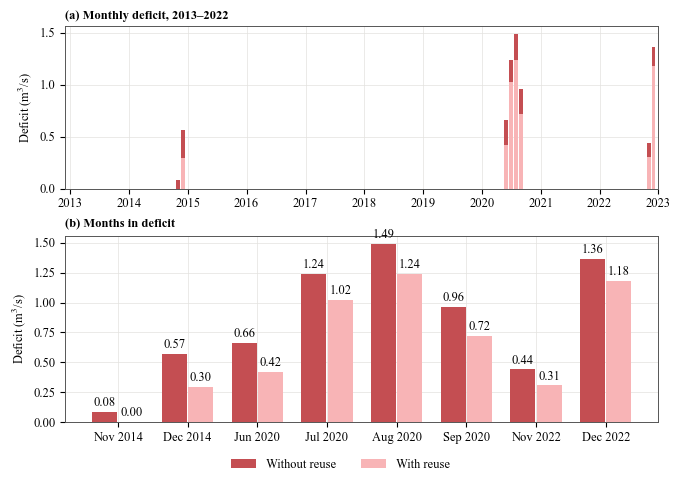

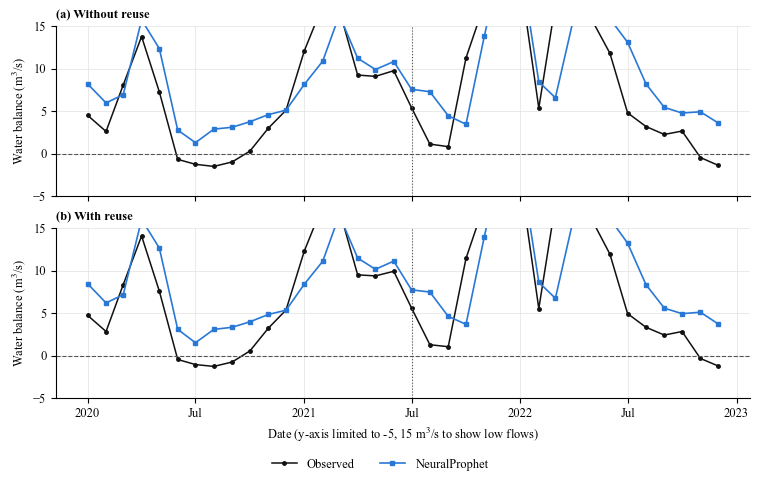

In [12]:
def save_figure(fig, name):
    fig.savefig(OUT / f'{name}.pdf', bbox_inches='tight')
    fig.savefig(OUT / f'{name}.png', dpi=300, bbox_inches='tight')
    plt.show()


plt.rcParams.update({
    'font.family': 'Times New Roman',
    'font.size': 9,
    'axes.labelsize': 9,
    'axes.titlesize': 9,
    'xtick.labelsize': 9,
    'ytick.labelsize': 9,
    'legend.fontsize': 9,
    'mathtext.fontset': 'stix',
    'pdf.fonttype': 42,
    'ps.fonttype': 42,
})


# Colori
WITHOUT = '#C44E52'    # Rosso
WITH = '#F8B4B6'       # Rosso chiaro
GRID_COLOR = '#E3E2DE'


cm = 1 / 2.54

fig, axes = plt.subplots(
    2, 1,
    figsize=(17 * cm, 12 * cm),
    constrained_layout=True,
    height_ratios=[1, 1.15]
)

ax = axes[0]

ax.bar(
    model_period.ds,
    model_period.Deficit_no_reuse,
    width=24,
    color=WITHOUT,
    label='Without reuse',
    zorder=3
)

ax.bar(
    model_period.ds,
    model_period.Deficit_reuse,
    width=24,
    color=WITH,
    label='With reuse',
    zorder=4
)

ax.set_xlim(
    model_period.ds.min() - pd.DateOffset(months=1),
    model_period.ds.max() + pd.DateOffset(months=1)
)

ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

ax.set_ylabel(r'Deficit (m$^3$/s)')

ax.text(
    0, 1.03,
    '(a) Monthly deficit, 2013–2022',
    transform=ax.transAxes,
    fontweight='bold',
    fontsize=9,
    va='bottom'
)
ax = axes[1]

shown = deficit_months[
    deficit_months.ds <= LAST_MODEL_MONTH
]

x = np.arange(len(shown))

ax.bar(
    x - 0.19,
    shown.Deficit_no_reuse,
    width=0.36,
    color=WITHOUT,
    label='Without reuse',
    zorder=3
)

ax.bar(
    x + 0.19,
    shown.Deficit_reuse,
    width=0.36,
    color=WITH,
    label='With reuse',
    zorder=3
)

for xi, (before, after) in enumerate(
    zip(shown.Deficit_no_reuse, shown.Deficit_reuse)
):
    ax.text(
        xi - 0.19,
        before + 0.025,
        f'{before:.2f}',
        ha='center',
        va='bottom',
        fontsize=9
    )

    ax.text(
        xi + 0.19,
        after + 0.025,
        f'{after:.2f}',
        ha='center',
        va='bottom',
        fontsize=9
    )

ax.set_xticks(
    x,
    shown.ds.dt.strftime('%b %Y')
)

ax.set_ylabel(r'Deficit (m$^3$/s)')

ax.text(
    0, 1.03,
    '(b) Months in deficit',
    transform=ax.transAxes,
    fontweight='bold',
    fontsize=9,
    va='bottom'
)

for ax in axes:

    ax.grid(
        True,
        axis='both',
        color=GRID_COLOR,
        linestyle='-',
        linewidth=0.5
    )

    ax.set_axisbelow(True)

    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_color('#555555')
        spine.set_linewidth(0.7)

    ax.tick_params(
        axis='both',
        labelsize=9,
        direction='out'
    )

handles, labels = axes[1].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc='outside lower center',
    ncol=2,
    frameon=False,
    fontsize=9
)

save_figure(fig, 'Figure_8')

plt.show()

monthly = q_forecasts.sort_values('ds')
fig, axes = plt.subplots(2, 1, figsize=(19 * cm, 12 * cm), constrained_layout=True, sharex=True)
for ax, (observed, forecast, title) in zip(axes, [('Balance_no_reuse', 'Forecast_no_reuse', '(a) Without reuse'), ('Balance_reuse', 'Forecast_reuse', '(b) With reuse')]):
    ax.plot(monthly.ds, monthly[observed], color=OBSERVED, lw=1.1, marker='o', ms=2.5, label='Observed')
    ax.plot(monthly.ds, monthly[forecast], color='#2a78d6', lw=1.2, marker='s', ms=2.5, label='NeuralProphet')
    ax.axhline(0, color='#555555', lw=0.8, ls='--')
    ax.axvline(hydro_series.ds.iloc[b], color='#555555', lw=0.8, ls=':')
    ax.set_ylim(-5, 15)
    ax.set_ylabel('Water balance (m$^3$/s)')
    ax.text(0, 1.03, title, transform=ax.transAxes, fontweight='bold', va='bottom')
    ax.grid(color='#E3E2DE', lw=0.5)
    ax.spines[['top', 'right']].set_visible(False)
axes[-1].xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=9))
axes[-1].xaxis.set_major_formatter(mdates.ConciseDateFormatter(axes[-1].xaxis.get_major_locator()))
axes[-1].set_xlabel('Date (y-axis limited to -5, 15 m$^3$/s to show low flows)')

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='outside lower center', ncol=2, frameon=False)
save_figure(fig, 'Figure_forecast_balance_low_flows')


## 5. Deficit Probability

The probability is derived from NeuralProphet’s past errors. The alert threshold is determined based on the validation set and applied to the test set. The historical monthly frequency of deficits serves solely as a reference for the Brier skill score.


Punteggi delle probabilita


,Period,Case,N,Observed_deficits,Expected_deficits,Brier,Brier_skill,AUC
0,Validation,Without reuse,18,4,1.50,0.128,0.432,0.964
1,Validation,With reuse,18,4,1.20,0.148,0.336,0.920
2,Test,Without reuse,18,2,0.80,0.081,0.131,0.938
3,Test,With reuse,18,2,0.65,0.090,0.146,0.891
4,Validation + test,Without reuse,36,6,2.30,0.104,0.344,0.953
5,Validation + test,With reuse,36,6,1.85,0.119,0.275,0.922


Allerta con soglia scelta sulla validazione


,Case,Threshold,Period,Hits,Misses,False_alarms,CSI
0,Without reuse,0.1,Validation,4,0,2,0.667
1,Without reuse,0.1,Test,2,0,2,0.500
2,With reuse,0.1,Validation,4,0,2,0.667
3,With reuse,0.1,Test,1,1,1,0.333


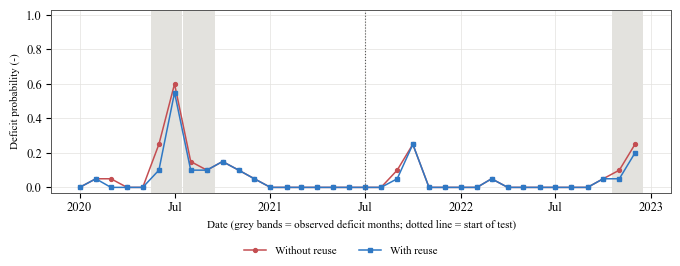

In [13]:


def deficit_probability(period, dates, forecast_balance):
    allowed = ['Training'] if period == 'Validation' else ['Training', 'Validation']
    rows = stored[stored.Partition.isin(allowed)].groupby('ds').agg(Observed=('Observed', 'first'), Predicted=('Predicted', 'mean'))
    rows['Error'] = rows.Observed - rows.Predicted
    level = stored[stored.Partition == period].groupby('ds').Predicted.mean().reindex(dates).values
    result = []
    for x, balance_hat in zip(level, forecast_balance):
        nearest = rows.iloc[np.argsort(np.abs(rows.Predicted.values - x))[:20]]
        result.append(float(np.mean(balance_hat + nearest.Error.values < 0)))
    return np.array(result)


probability_rows = []
for period, (start, end) in PERIODS.items():
    dates = hydro_series.ds.iloc[start:end].reset_index(drop=True)
    fit_balance = balance[balance.ds < dates.iloc[0]]
    observed_all = balance.set_index('ds').reindex(dates)
    forecast_rows = q_forecasts[q_forecasts.Period == period].set_index('ds').reindex(dates)
    for case, column_obs, column_hat, column_fit in [('Without reuse', 'Balance_no_reuse', 'Forecast_no_reuse', 'Deficit_no_reuse'),
                                                     ('With reuse', 'Balance_reuse', 'Forecast_reuse', 'Deficit_reuse')]:
        monthly_frequency = (fit_balance[column_fit] > 0).groupby(fit_balance.ds.dt.month).mean()
        probability_rows.append(pd.DataFrame(dict(Period=period, Case=case, ds=dates.values,
                                                  Probability=deficit_probability(period, dates, forecast_rows[column_hat].values),
                                                  Reference=dates.dt.month.map(monthly_frequency).fillna(0).values,
                                                  Deficit=(observed_all[column_obs].values < 0).astype(int))))
probabilities = pd.concat(probability_rows, ignore_index=True)
probabilities.to_csv(OUT / 'Deficit_probabilities.csv', index=False)


def probability_scores(g):
    reference = np.mean((g.Deficit - g.Reference) ** 2)
    brier = np.mean((g.Deficit - g.Probability) ** 2)
    return dict(N=len(g), Observed_deficits=int(g.Deficit.sum()), Expected_deficits=float(g.Probability.sum()), Brier=float(brier),
                Brier_skill=float(1 - brier / reference) if reference > 0 else np.nan,
                AUC=float(roc_auc_score(g.Deficit, g.Probability)) if 0 < g.Deficit.sum() < len(g) else np.nan)


score_rows = [dict(Period=p, Case=c, **probability_scores(g)) for (p, c), g in probabilities.groupby(['Period', 'Case'], sort=False)]
score_rows += [dict(Period='Validation + test', Case=c, **probability_scores(g)) for c, g in probabilities.groupby('Case', sort=False)]
probability_summary = pd.DataFrame(score_rows)
probability_summary.to_csv(OUT / 'Deficit_probability_scores.csv', index=False)


def contingency(g, threshold):
    alert, event = g.Probability >= threshold, g.Deficit == 1
    hits, misses, alarms = int((alert & event).sum()), int((~alert & event).sum()), int((alert & ~event).sum())
    return dict(Hits=hits, Misses=misses, False_alarms=alarms, CSI=hits / (hits + misses + alarms) if hits + misses + alarms else 0.0)


alert_rows = []
for case, g in probabilities.groupby('Case', sort=False):
    validation, test = g[g.Period == 'Validation'], g[g.Period == 'Test']
    best = max(np.arange(0.05, 0.96, 0.05), key=lambda t: (contingency(validation, t)['CSI'], t))
    alert_rows.append(dict(Case=case, Threshold=round(float(best), 2), Period='Validation', **contingency(validation, best)))
    alert_rows.append(dict(Case=case, Threshold=round(float(best), 2), Period='Test', **contingency(test, best)))
alert_table = pd.DataFrame(alert_rows)
alert_table.to_csv(OUT / 'Deficit_alert_scores.csv', index=False)
print('Punteggi delle probabilita'); display(probability_summary.round(3))
print('Allerta con soglia scelta sulla validazione'); display(alert_table.round(3))


plt.rcParams.update({
    'font.family': 'Times New Roman',
    'font.size': 9,
    'axes.labelsize': 9,
    'axes.titlesize': 9,
    'xtick.labelsize': 9,
    'ytick.labelsize': 9,
    'legend.fontsize': 9,
    'mathtext.fontset': 'stix',
    'pdf.fonttype': 42,
    'ps.fonttype': 42,
})


WITH = '#2F78C4'  
WITHOUT = '#C44E52'    

cm = 1 / 2.54
fig, ax = plt.subplots(
    figsize=(17 * cm, 6.5 * cm),
    constrained_layout=True
)

events = probabilities[
    (probabilities.Case == 'Without reuse') &
    (probabilities.Deficit == 1)
]

for date in events.ds:
    ax.axvspan(
        date - pd.Timedelta(days=15),
        date + pd.Timedelta(days=15),
        color='#E3E2DE',
        lw=0,
        zorder=0
    )

for case, color, marker in [
    ('Without reuse', WITHOUT, 'o'),
    ('With reuse', WITH, 's')
]:
    g = probabilities[
        probabilities.Case == case
    ].sort_values('ds')

    ax.plot(
        g.ds,
        g.Probability,
        color=color,
        marker=marker,
        ms=2.8,
        lw=1.1,
        label=case
    )

ax.axvline(
    hydro_series.ds.iloc[b],
    color='#555555',
    ls=':',
    lw=0.8
)

ax.set_ylim(-0.03, 1.03)
ax.set_ylabel('Deficit probability (-)', fontsize=8)

ax.grid(color='#E3E2DE', lw=0.5)

for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_color('#555555')
    spine.set_linewidth(0.7)

ax.xaxis.set_major_locator(
    mdates.AutoDateLocator(maxticks=9)
)
ax.xaxis.set_major_formatter(
    mdates.ConciseDateFormatter(
        ax.xaxis.get_major_locator()
    )
)

ax.set_xlabel(
    'Date (grey bands = observed deficit months; dotted line = start of test)',
    fontsize=8
)

fig.legend(
    loc='outside lower center',
    ncol=2,
    frameon=False,
    fontsize=8
)

save_figure(fig, 'Figure_10')
